# Drone power draw prediction via flight sensor information

My mission is to solve problems by using computation. I achieve that by using tools such as python, C/C++, calculus, linear algebra, fusion, etc to attack various problems in engineering, science, or machine learning and improve productivity.

This project is aimed to be used by mechatronics engineers, AI researchers, etc to predict how much power would a drone need based on flight informat   

In [ ]:
!uv pip install numpy pandas scipy matplotlib seaborn scikit-learn statsmodels jupyter ipykernel

## Task 1.1: Data preparation and exploration

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project root directory
PROJECT_ROOT = Path.cwd().parent.parent

# Data directories
DATA_DIR = PROJECT_ROOT / "data"
FLIGHTS_DIR = DATA_DIR / "flights"
PARAMETERS_PATH = DATA_DIR / "parameters.csv"

# print("Project root:", PROJECT_ROOT)
# print("Data directory:", DATA_DIR)

In [3]:
def load_dataset(flights_dir, parameters_path):
    """
    Load per-flight sensor logs and the flight-level parameters.

    Returns:
        flights_df: All flight observations stacked, with a `flight` ID column.
        parameters_df: One row per flight (speed, payload, altitude, ...).
    """
    flights_dir = Path(flights_dir)

    parameters_df = pd.read_csv(parameters_path)

    # Only numeric filenames (e.g. 12.csv), sorted numerically, not alphabetically
    flight_files = sorted(
        (f for f in flights_dir.glob("*.csv") if f.stem.isdigit()),
        key=lambda f: int(f.stem),
    )
    if not flight_files:
        raise FileNotFoundError(f"No flight CSV files found in {flights_dir}")

    flights_df = pd.concat(
        (pd.read_csv(f).assign(flight=int(f.stem)) for f in flight_files),
        ignore_index=True,
    )

    return flights_df, parameters_df


flights_df, parameters_df = load_dataset(FLIGHTS_DIR, PARAMETERS_PATH)

In [4]:
print(f"Loaded {flights_df['flight'].nunique()} flights")
print(f"Combined dataset shape: {flights_df.shape}")

Loaded 209 flights
Combined dataset shape: (257896, 22)


In [5]:
# Every flight log should have a parameters row, and vice versa
log_ids = set(flights_df["flight"])
param_ids = set(parameters_df["flight"])
print("Logs without parameters:", sorted(log_ids - param_ids))
print("Parameters without logs:", sorted(param_ids - log_ids))

assert parameters_df["flight"].is_unique, "Duplicate flight IDs in parameters.csv"

data_df = flights_df.merge(parameters_df, on="flight", how="left", validate="many_to_one")

print(f"Loaded {flights_df['flight'].nunique()} flights")
print(f"Flight logs shape: {flights_df.shape}")
print(f"Merged dataset shape: {data_df.shape}")

Logs without parameters: []
Parameters without logs: []
Loaded 209 flights
Flight logs shape: (257896, 22)
Merged dataset shape: (257896, 28)


In [6]:
data_df.info()

display(data_df.describe().T)  # transposed: easier to read with ~25 columns

missing = data_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print("No missing values.")
else:
    display(missing.to_frame("missing").assign(pct=lambda d: 100 * d["missing"] / len(data_df)))

# Observations per flight
rows_per_flight = data_df["flight"].value_counts().sort_index()
display(rows_per_flight.describe())

<class 'pandas.DataFrame'>
RangeIndex: 257896 entries, 0 to 257895
Data columns (total 28 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   time                   257896 non-null  float64
 1   wind_speed             257896 non-null  float64
 2   wind_angle             257896 non-null  float64
 3   battery_voltage        257896 non-null  float64
 4   battery_current        257896 non-null  float64
 5   position_x             257896 non-null  float64
 6   position_y             257896 non-null  float64
 7   position_z             257896 non-null  float64
 8   orientation_x          257896 non-null  float64
 9   orientation_y          257896 non-null  float64
 10  orientation_z          257896 non-null  float64
 11  orientation_w          257896 non-null  float64
 12  velocity_x             257896 non-null  float64
 13  velocity_y             257896 non-null  float64
 14  velocity_z             257896 non-null  float64

,count,mean,std,min,25%,50%,75%,max
time,257896.0,97.766940,62.667401,0.000000e+00,46.200000,93.000000,141.400000,428.290000
wind_speed,257896.0,4.337992,3.494649,0.000000e+00,1.500000,3.300000,6.500000,18.100000
wind_angle,257896.0,169.470760,101.176006,0.000000e+00,80.000000,177.000000,244.000000,359.000000
battery_voltage,257896.0,22.435459,1.200742,1.881081e+01,21.513987,22.306536,23.162939,25.894913
battery_current,257896.0,17.932477,10.865654,-3.260227e-01,7.140693,21.923040,25.270737,47.193779
position_x,257896.0,-77.773754,12.506800,-7.994654e+01,-79.782786,-79.782747,-79.782259,0.000000
position_y,257896.0,39.438805,6.342148,0.000000e+00,40.458878,40.458994,40.459057,40.459682
position_z,257896.0,295.812932,58.305928,0.000000e+00,271.311215,292.120051,325.245442,376.188721
orientation_x,257896.0,-0.010096,0.047414,-5.464130e-01,-0.023949,-0.001910,0.010370,0.414962
orientation_y,257896.0,-0.010531,0.045168,-2.791741e-01,-0.025285,-0.003945,0.009010,0.538922


No missing values.


count     209.000000
mean     1233.952153
std       293.374740
min       391.000000
25%      1045.000000
50%      1207.000000
75%      1374.000000
max      2856.000000
Name: count, dtype: float64

### Target definition: power in watts

We can notice two apparent clusters in power, one near 0W and the second around 450-550W. The mean wattage per flight falls under a slightly smaller range, this could clue us that most variations happens within a flight. We might add a `flight_phase` feature later to capture the different flight state neatly.

count    257896.000000
mean        393.406742
std         236.649152
min          -8.341506
25%         164.560906
50%         483.241611
75%         552.684146
max        1004.217668
Name: power, dtype: float64

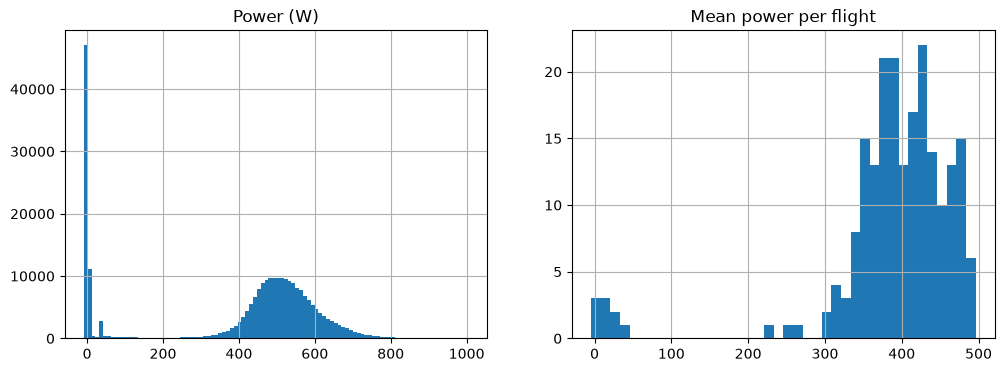

In [7]:
data_df["power"] = data_df["battery_voltage"] * data_df["battery_current"]

display(data_df["power"].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

data_df["power"].hist(bins=100, ax=ax[0]); ax[0].set_title("Power (W)")
data_df.groupby("flight")["power"].mean().hist(bins=40, ax=ax[1]); ax[1].set_title("Mean power per flight")
plt.show()

### Data quality checks

In [8]:
print("Negative current rows:", (data_df["battery_current"] < 0).sum())

for c in ["position_x", "position_y", "position_z"]:
    print(c, "== 0 rows:", (data_df[c] == 0).sum(), "| flights:", data_df.loc[data_df[c] == 0, "flight"].nunique())
    
q = data_df[["orientation_x","orientation_y","orientation_z","orientation_w"]]

print("Quaternion norm range:", np.linalg.norm(q, axis=1).min(), np.linalg.norm(q, axis=1).max())
print("Duplicated rows:", data_df.duplicated().sum())

display(data_df["altitude"].value_counts())

dt = data_df.groupby("flight")["time"].diff()
display(dt.describe())   # sampling interval: should be about 0.2 s

Negative current rows: 29031
position_x == 0 rows: 6501 | flights: 9
position_y == 0 rows: 6501 | flights: 9
position_z == 0 rows: 6501 | flights: 9
Quaternion norm range: 0.9999999116412253 1.0000001442569149
Duplicated rows: 0


altitude
100             64666
75              61805
50              60279
25              58666
0                6501
3                3794
25-50-100-25     2185
Name: count, dtype: int64

count    257687.000000
mean          0.150250
std           0.053285
min           0.060000
25%           0.100000
50%           0.120000
75%           0.200000
max           5.280000
Name: time, dtype: float64

### Flight-level parameters (one row per flight)

In [9]:
display(pd.crosstab(parameters_df["speed"], parameters_df["payload"]))
display(pd.crosstab(parameters_df["route"], parameters_df["altitude"]))

payload,0.0,250.0,500.0,750.0
speed,,,,
0.0,13,0,0,0
4.0,14,13,13,1
6.0,13,12,13,0
8.0,12,12,12,0
10.0,15,13,15,0
12.0,13,12,13,0


altitude,0,100,25,25-50-100-25,3,50,75
route,,,,,,,
A1,3,0,0,0,0,0,0
A2,3,0,0,0,0,0,0
A3,3,0,0,0,0,0,0
H,0,0,0,0,4,0,0
R1,0,45,45,0,0,46,46
R2,0,0,1,0,0,0,0
R3,0,0,1,0,0,0,0
R4,0,0,1,0,0,0,0
R5,0,0,3,0,0,1,0


### Power over time for a few flights

The power is idle at first then jumps during takeoff, and drops to about 0 after the landing. We can see that the power follows the altitude curve. This tells us that the flight phase and height matters a lot for out predictions.

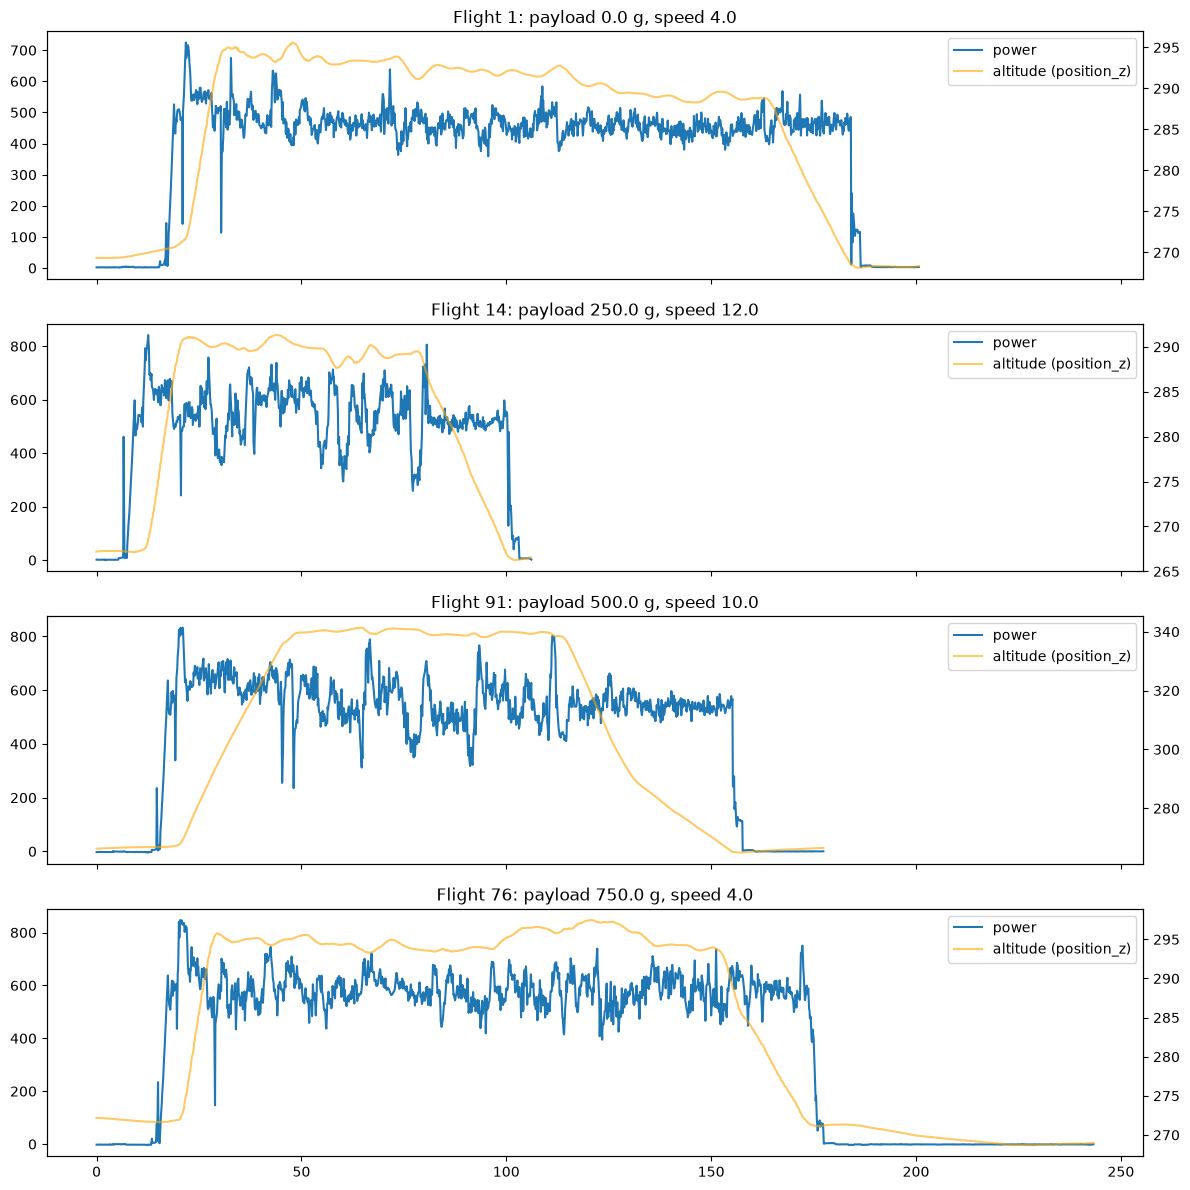

In [10]:
import seaborn as sns

sample = parameters_df.groupby("payload")["flight"].first().tolist()
fig, axes = plt.subplots(len(sample), 1, figsize=(12, 3*len(sample)), sharex=True)

for ax, f in zip(axes, sample):
    d = data_df[data_df["flight"] == f]
    ax.plot(d["time"], d["power"], label="power")
    ax2 = ax.twinx()
    ax2.plot(d["time"], d["position_z"], color="orange", alpha=.6, label="altitude (position_z)")
    ax.set_title(f"Flight {f}: payload {d['payload'].iat[0]} g, speed {d['speed'].iat[0]}")

    # Combine the lines from both axes into one legend
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper right")

plt.tight_layout(); plt.show()

### Power against each predictor

The median power rises as the payload gets heavier: 0 -> 250 -> 500 g (row means 365 -> 408 -> 440 W). We discard the 750g payload parameter since it's only one flight. In addition, speed doesn't give off any useful trend (r = −0.03) and altitude shows very small fluctuations (387–421 W).

**Decision**: keep payload numeric; keep speed despite its weak link for later feature engineering; treat altitude as labels.

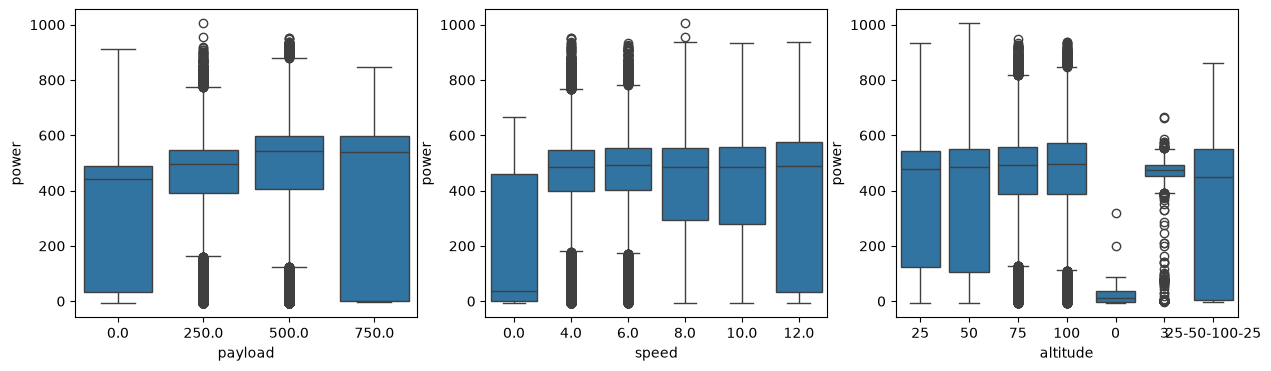

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=data_df, x="payload", y="power", ax=axes[0])
sns.boxplot(data=data_df, x="speed", y="power", ax=axes[1])
sns.boxplot(data=data_df, x="altitude", y="power", ax=axes[2])
plt.show()

### Correlation and multicollinearity

We can observe a near perfect correlation between `battery_current` and `power` (r = 0.997), that's because power is computed from **voltage * current**. The heatmap also shows high correlation between `position_x` and `position_y`, but that comes from the 9 flights with (0, 0) GPS readings. Without consideting the aforementionned correlations, the strongest links are `position_z` (0.50), `wind_speed`(0.48) and `velocity_y` (0.34).

**Decision**: drop current and voltage as they leak the target, drop raw GPS, and use height for the scatter plots before and after the fit.

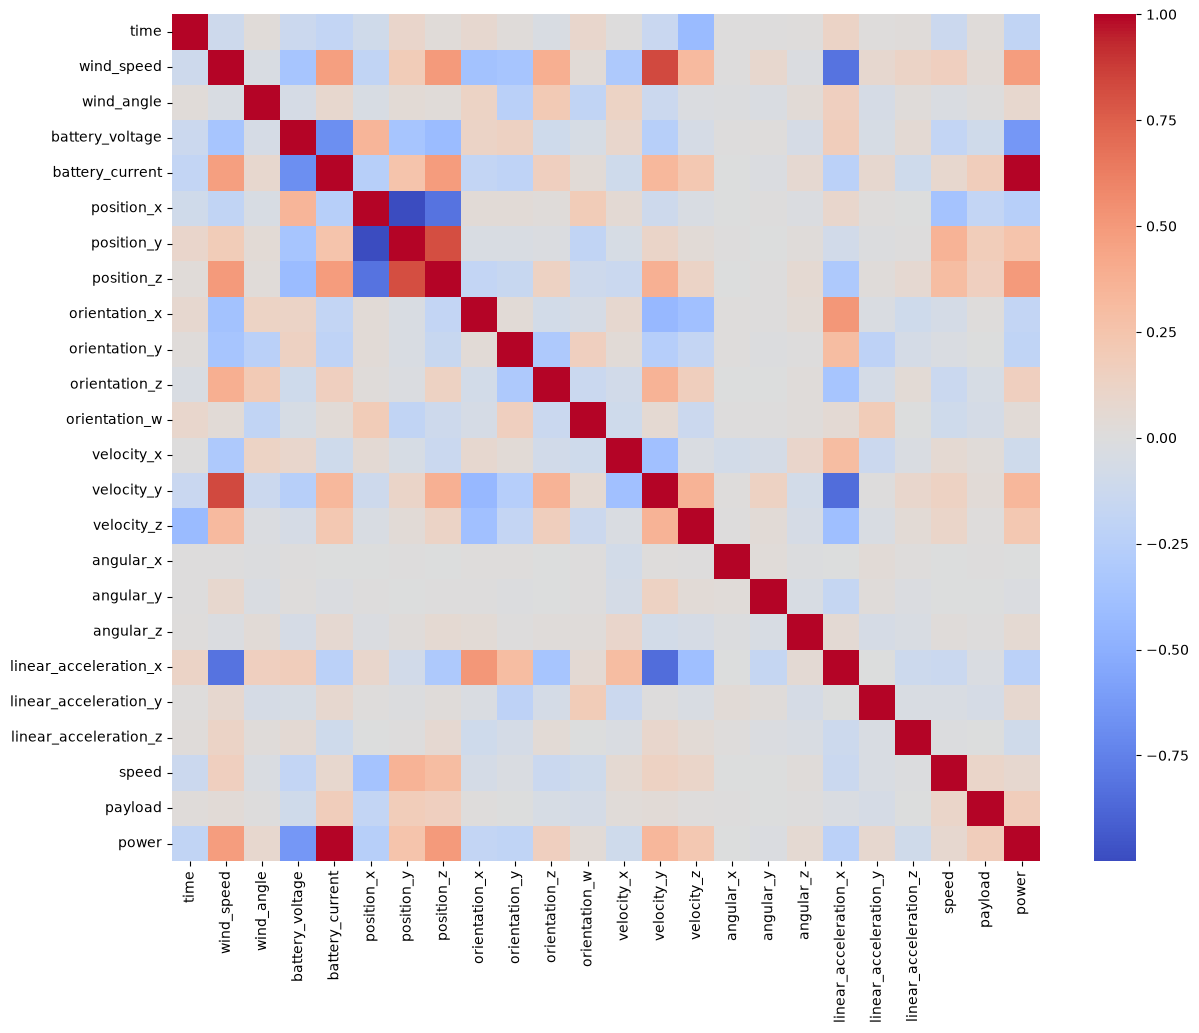

battery_current          0.997022
battery_voltage         -0.639479
position_z               0.496799
wind_speed               0.479005
velocity_y               0.337205
position_x              -0.257301
position_y               0.257280
linear_acceleration_x   -0.228275
velocity_z               0.225852
orientation_y           -0.203067
time                    -0.190578
orientation_x           -0.181636
payload                  0.171903
orientation_z            0.159264
velocity_x              -0.105972
linear_acceleration_z   -0.100247
wind_angle               0.083061
linear_acceleration_y    0.072014
speed                    0.071127
angular_z                0.061403
orientation_w            0.032400
angular_y               -0.018338
angular_x               -0.005847
Name: power, dtype: float64

In [12]:
num = data_df.select_dtypes("number").drop(columns=["flight"])
plt.figure(figsize=(14, 11))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=False); plt.show()
display(num.corr()["power"].drop("power").sort_values(key=abs, ascending=False))

## Task 1.2: Feature engineering

### Remove flights with weird properties

In [13]:
# Flight 211 to 219, routes A1-A3 have their GPS logged as exactly 0, it is most likely a sensor failure, not real positions
bad_gps = data_df.loc[(data_df["position_x"] == 0) & (data_df["position_y"] == 0), "flight"].unique()

before = len(data_df)
data_df = data_df[~data_df["flight"].isin(bad_gps)].copy()
print(f"Rows: {before:,} -> {len(data_df):,} | flights left: {data_df['flight'].nunique()}")

display(data_df.groupby("route").agg(flights=("flight", "nunique"), rows=("flight", "size"))
        .sort_values("rows", ascending=False))

Rows: 257,896 -> 251,395 | flights left: 200


,flights,rows
route,,
R1,182,227551
R6,5,8369
R5,4,5490
H,4,3794
R7,2,2185
R2,1,1445
R3,1,1364
R4,1,1197


### Engineer new numerical features

In [14]:
data_df["ground_speed"] = np.hypot(data_df["velocity_x"], data_df["velocity_y"])

qx, qy = data_df["orientation_x"], data_df["orientation_y"]
data_df["tilt_deg"] = np.degrees(np.arccos(np.clip(1 - 2 * (qx**2 + qy**2), -1, 1)))

data_df["height"] = data_df["position_z"] - data_df.groupby("flight")["position_z"].transform("first")

### Categorical feature 1: flight phase

In [15]:
# Motor vibration: rolling std (about 1 s) of the acceleration magnitude.
# Motors off -> about 0.001; motors on -> about 0.16 (median).
acc = data_df[["linear_acceleration_x", "linear_acceleration_y", "linear_acceleration_z"]].to_numpy()
data_df["acc_norm"] = np.linalg.norm(acc, axis=1)
data_df["vibration"] = (data_df.groupby("flight")["acc_norm"]
                        .transform(lambda s: s.rolling(5, center=True, min_periods=1).std()))

MOTORS_OFF = 0.02 # threshold chosen from the vibration distribution
vz, gs = data_df["velocity_z"], data_df["ground_speed"]

# Checked in order: the first condition that is true sets the label
data_df["flight_phase"] = np.select(
    [data_df["vibration"] < MOTORS_OFF, vz > 0.5, vz < -0.5, gs > 1.0],
    ["ground", "climb",  "descent",  "cruise"],
    default="hover",
)

display(data_df.groupby("flight_phase")["power"].agg(rows="size", mean_W="mean", std_W="std").round(1))

,rows,mean_W,std_W
flight_phase,,,
climb,80172,552.5,92.8
cruise,38902,502.1,66.4
descent,54983,500.4,78.8
ground,56871,8.3,50.9
hover,20467,466.7,155.5


### Categorical features 2 and 3: route and altitude

In [16]:
data_df["route"] = np.where(data_df["route"].isin(["R1", "H"]), data_df["route"], "other")
data_df["altitude"] = data_df["altitude"].astype(str)   # "25","50","75","100","3","25-50-100-25"

display(data_df.groupby("route")["flight"].nunique())

route
H          4
R1       182
other     14
Name: flight, dtype: int64

### Drop the columns we will not use

Check the comments for the reasons

In [17]:
DROP_COLS = [
    "date", "local_time",                              # calendar/clock time with no physical effect
    "position_x", "position_y", "position_z",          # GPS longitude and latitude which will be replaced by height
    "orientation_x", "orientation_y",
    "orientation_z", "orientation_w",                  # quaternion, replaced by tilt_deg
    "velocity_x", "velocity_y",                        # direction-dependent, replaced by ground_speed
    "angular_x", "angular_y", "angular_z",             # noisy spin rates, |r| < 0.07
    "linear_acceleration_x", "linear_acceleration_y",
    "linear_acceleration_z", "acc_norm", "vibration",  # only used to label flight_phase
    "wind_angle",                                      # |r| = 0.08, measured in the drone's own frame
]
data_df = data_df.drop(columns=DROP_COLS)

### Final feature list

In [18]:
NUMERIC_FEATURES = ["payload", "speed", "wind_speed", "ground_speed",
                    "velocity_z", "tilt_deg", "height", "time"]
CATEGORICAL_FEATURES = ["route", "flight_phase", "altitude"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES      # 11 inputs
TARGET = "power"

display(data_df[NUMERIC_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
        .sort_values(key=abs, ascending=False).to_frame("r with power"))
display(data_df[NUMERIC_FEATURES].agg(["min", "max"]).T)   # use these for the Pydantic ranges

,r with power
height,0.523804
wind_speed,0.453103
ground_speed,0.338878
tilt_deg,0.329670
time,-0.225547
velocity_z,0.225161
payload,0.131323
speed,-0.025940


,min,max
payload,0.000000,750.000000
speed,0.000000,12.000000
wind_speed,0.000000,18.100000
ground_speed,0.000014,12.711181
velocity_z,-4.015751,5.842570
tilt_deg,0.005366,67.101639
height,-13.789597,107.730422
time,0.000000,428.290000


### Split the data

In [19]:
from sklearn.model_selection import StratifiedGroupKFold

# One fold of 5 = about 20% test; this seed puts every route group (R1, H, other) in the test set
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=5)
train_idx, test_idx = next(sgkf.split(data_df, y=data_df["route"], groups=data_df["flight"]))

train_df, test_df = data_df.iloc[train_idx], data_df.iloc[test_idx]
assert set(train_df["flight"]).isdisjoint(test_df["flight"])

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")

Train: 200,288 rows | Test: 51,107 rows


### Final list of inputs

| Field | Type | Unit | Meaning | Observed (min – max) | 99% of rows | **Allowed** |
|---|---|---|---|---|---|---|
| `payload` | float | g | Mass of the parcel carried | 0 – 750 (only 0, 250, 500, 750) | 0 – 500 | **0 – 750** |
| `speed` | float | m/s | Programmed cruise ground speed | 0 – 12 (only 0, 4, 6, 8, 10, 12) | 0 – 12 | **0 – 12** |
| `wind_speed` | float | m/s | Wind speed from the onboard anemometer | 0 – 18.1 | 0.2 – 13.9 | **0 – 20** |
| `ground_speed` | float | m/s | Horizontal speed, √(vx² + vy²) | 0 – 12.7 | 0 – 11.5 | **0 – 13** |
| `velocity_z` | float | m/s | Vertical speed (+ up, − down) | −4.0 – 5.8 | −3.1 – 3.6 | **−5 – 6** |
| `tilt_deg` | float | ° | Tilt from level, from the quaternion | 0 – 67.1 | 0.3 – 23.3 | **0 – 45** |
| `height` | float | m | Height above the take-off point | −13.8 – 107.7 | −4.9 – 102.0 | **−15 – 120** |
| `time` | float | s | Seconds since logging started | 0 – 428.3 | 1.8 – 252.2 | **0 – 450** |


### Categorical inputs

| Field | Type | Allowed values | Meaning |
|---|---|---|---|
| `route` | string enum | `"R1"`, `"H"`, `"other"` | R1 is the main delivery route (182 flights). H is hover-only. `other` groups routes R2–R7. |
| `flight_phase` | string enum | `"ground"`, `"climb"`, `"cruise"`, `"hover"`, `"descent"` | What the drone is doing at that moment |
| `altitude` | string enum | `"3"`, `"25"`, `"50"`, `"75"`, `"100"`, `"25-50-100-25"` | Programmed cruise altitude in m. It is a string because of the multi-level profile. |


### Target (only in `/retrain`)

| Field | Type | Unit | Observed | **Allowed** |
|---|---|---|---|---|
| `power` | float | W | −7.7 – 1004.2 (99%: −3.1 – 743.9) | **−10 – 1100** |